In [87]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("bbdc_2018/train-en.csv")
#df = pd.read_csv("bbdc_2018/eval-en.csv")
#df = pd.read_csv("bbdc_2018/challenge-en.csv")

In [88]:
df

,Date,wind_speed48M,wind_speed100M,wind_speed152M,wind_direction48M,wind_direction100M,wind_direction152M,wind_speed_100MP10,wind_speed_100MP20,wind_speed_100MP30,wind_speed_100MP40,wind_speed_100MP50,wind_speed_100MP60,wind_speed_100MP70,wind_speed_100MP80,wind_speed_100MP90,Interpolated,available_capacity,Output
0,2016-01-01 0:00:00,8.490,10.7700,12.690,188.00,190.00,194.00,9.0700,9.6300,10.0600,10.43,10.7800,11.0500,11.5400,11.9400,12.4200,0,122400,79168
1,2016-01-01 0:15:00,8.395,10.6175,12.475,190.75,193.00,196.75,9.0425,9.5550,9.9550,10.31,10.6300,10.9275,11.3875,11.8150,12.3125,1,122400,75124
2,2016-01-01 0:30:00,8.300,10.4650,12.260,193.50,196.00,199.50,9.0150,9.4800,9.8500,10.19,10.4800,10.8050,11.2350,11.6900,12.2050,1,122400,76072
3,2016-01-01 0:45:00,8.205,10.3125,12.045,196.25,199.00,202.25,8.9875,9.4050,9.7450,10.07,10.3300,10.6825,11.0825,11.5650,12.0975,1,122400,67964
4,2016-01-01 1:00:00,8.110,10.1600,11.830,199.00,202.00,205.00,8.9600,9.3300,9.6400,9.95,10.1800,10.5600,10.9300,11.4400,11.9900,0,122400,69988
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52503,2017-06-30 22:45:00,4.920,5.9475,6.580,269.25,271.25,272.50,4.5700,5.0375,5.4325,5.73,6.0125,6.2125,6.4175,6.7325,7.2175,1,119000,13688
52504,2017-06-30 23:00:00,5.030,6.0900,6.730,269.00,271.00,272.00,4.6800,5.1800,5.5700,5.87,6.1600,6.3600,6.5700,6.8700,7.3500,0,119000,17624
52505,2017-06-30 23:15:00,5.030,6.0900,6.730,269.00,271.00,272.00,4.6800,5.1800,5.5700,5.87,6.1600,6.3600,6.5700,6.8700,7.3500,1,119000,18528
52506,2017-06-30 23:30:00,5.030,6.0900,6.730,269.00,271.00,272.00,4.6800,5.1800,5.5700,5.87,6.1600,6.3600,6.5700,6.8700,7.3500,1,119000,15836


In [89]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52508 entries, 0 to 52507
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                52508 non-null  object 
 1   wind_speed48M       52508 non-null  float64
 2   wind_speed100M      52508 non-null  float64
 3   wind_speed152M      52508 non-null  float64
 4   wind_direction48M   52508 non-null  float64
 5   wind_direction100M  52508 non-null  float64
 6   wind_direction152M  52508 non-null  float64
 7   wind_speed_100MP10  52508 non-null  float64
 8   wind_speed_100MP20  52508 non-null  float64
 9   wind_speed_100MP30  52508 non-null  float64
 10  wind_speed_100MP40  52508 non-null  float64
 11  wind_speed_100MP50  52508 non-null  float64
 12  wind_speed_100MP60  52508 non-null  float64
 13  wind_speed_100MP70  52508 non-null  float64
 14  wind_speed_100MP80  52508 non-null  float64
 15  wind_speed_100MP90  52508 non-null  float64
 16  Inte

In [90]:
#handle the missing values
df.isnull().sum()

Date                  0
wind_speed48M         0
wind_speed100M        0
wind_speed152M        0
wind_direction48M     0
wind_direction100M    0
wind_direction152M    0
wind_speed_100MP10    0
wind_speed_100MP20    0
wind_speed_100MP30    0
wind_speed_100MP40    0
wind_speed_100MP50    0
wind_speed_100MP60    0
wind_speed_100MP70    0
wind_speed_100MP80    0
wind_speed_100MP90    0
Interpolated          0
available_capacity    0
Output                0
dtype: int64

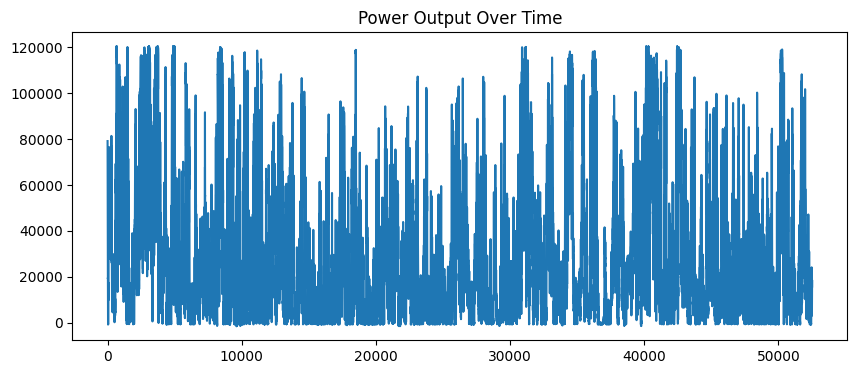

In [91]:
#understand the target values
plt.figure(figsize = (10,4))
plt.plot(df['Output'])
plt.title("Power Output Over Time")
plt.show()

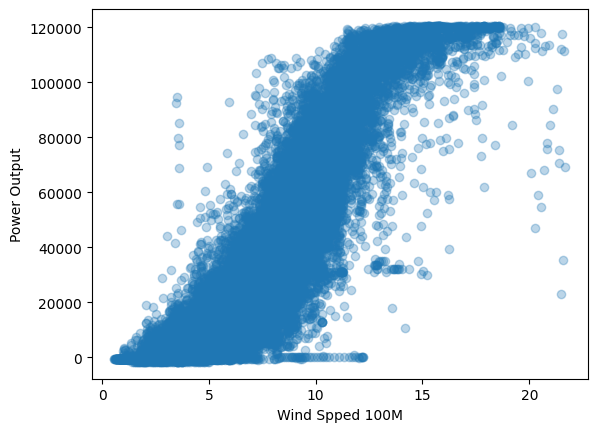

In [92]:
#most important plot: dictates enitore modeling strategy
plt.scatter(df['wind_speed100M'], df['Output'], alpha=0.3)
plt.xlabel("Wind Spped 100M")
plt.ylabel("Power Output")
plt.show()

In [93]:
#Now Feature engineering: 
#Time Feature
df['Date'] = pd.to_datetime(df['Date'], format='mixed')
df= df.sort_values('Date')
df.set_index('Date', inplace = True)
df['hour'] =df.index.hour
df['month'] = df.index.month

#Direction transformation: wind_direction
dir_cols = [col for col in df.columns if 'wind_direction' in col.lower()]

for col in dir_cols:
    df[col+ '_sin'] = np.sin(np.deg2rad(df[col]))
    df[col + '_cos'] = np.cos(np.deg2rad(df[col]))

    

In [94]:
df.drop(columns = dir_cols, inplace = True)

In [95]:
#Feature engineering
df['wind_Cube'] = df['wind_speed100M'] ** 3
#Windspeed engineering meaningful features before dropping
df['shear'] = df['wind_speed152M'] - df['wind_speed48M']
df['turbulence'] = df['wind_speed_100MP90'] - df["wind_speed_100MP10"]

#shear = difference between them which is already engineered so we are dropping these 
#columns
wind_speed_drop = [
    "wind_speed48M", "wind_speed152M",
    "wind_speed_100MP10", "wind_speed_100MP20", "wind_speed_100MP30",
    "wind_speed_100MP40", "wind_speed_100MP50", "wind_speed_100MP60",
    "wind_speed_100MP70", "wind_speed_100MP80", "wind_speed_100MP90"
]
df.drop(columns=wind_speed_drop, inplace=True)



In [96]:
df

,wind_speed100M,Interpolated,available_capacity,Output,hour,month,wind_direction48M_sin,wind_direction48M_cos,wind_direction100M_sin,wind_direction100M_cos,wind_direction152M_sin,wind_direction152M_cos,wind_Cube,shear,turbulence
Date,,,,,,,,,,,,,,,
2016-01-01 00:00:00,10.7700,0,122400,79168,0,1,-0.139173,-0.990268,-0.173648,-0.984808,-0.241922,-0.970296,1249.243533,4.20,3.3500
2016-01-01 00:15:00,10.6175,1,122400,75124,0,1,-0.186524,-0.982450,-0.224951,-0.974370,-0.288196,-0.957571,1196.924644,4.08,3.2700
2016-01-01 00:30:00,10.4650,1,122400,76072,0,1,-0.233445,-0.972370,-0.275637,-0.961262,-0.333807,-0.942641,1146.087295,3.96,3.1900
2016-01-01 00:45:00,10.3125,1,122400,67964,0,1,-0.279829,-0.960050,-0.325568,-0.945519,-0.378649,-0.925541,1096.710205,3.84,3.1100
2016-01-01 01:00:00,10.1600,0,122400,69988,1,1,-0.325568,-0.945519,-0.374607,-0.927184,-0.422618,-0.906308,1048.772096,3.72,3.0300
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017-06-30 22:45:00,5.9475,1,119000,13688,22,6,-0.999914,-0.013090,-0.999762,0.021815,-0.999048,0.043619,210.379468,1.66,2.6475
2017-06-30 23:00:00,6.0900,0,119000,17624,23,6,-0.999848,-0.017452,-0.999848,0.017452,-0.999391,0.034899,225.866529,1.70,2.6700
2017-06-30 23:15:00,6.0900,1,119000,18528,23,6,-0.999848,-0.017452,-0.999848,0.017452,-0.999391,0.034899,225.866529,1.70,2.6700


In [97]:
#── 3. WIND DIRECTION ─────────────────────────────────────────────────────────
# Keep 100M, drop 48M and 152M versions
direction_drop = [
    "wind_direction48M_sin",  "wind_direction48M_cos",
    "wind_direction152M_sin", "wind_direction152M_cos"
]
df.drop(columns=direction_drop, inplace=True)

In [98]:
df

,wind_speed100M,Interpolated,available_capacity,Output,hour,month,wind_direction100M_sin,wind_direction100M_cos,wind_Cube,shear,turbulence
Date,,,,,,,,,,,
2016-01-01 00:00:00,10.7700,0,122400,79168,0,1,-0.173648,-0.984808,1249.243533,4.20,3.3500
2016-01-01 00:15:00,10.6175,1,122400,75124,0,1,-0.224951,-0.974370,1196.924644,4.08,3.2700
2016-01-01 00:30:00,10.4650,1,122400,76072,0,1,-0.275637,-0.961262,1146.087295,3.96,3.1900
2016-01-01 00:45:00,10.3125,1,122400,67964,0,1,-0.325568,-0.945519,1096.710205,3.84,3.1100
2016-01-01 01:00:00,10.1600,0,122400,69988,1,1,-0.374607,-0.927184,1048.772096,3.72,3.0300
...,...,...,...,...,...,...,...,...,...,...,...
2017-06-30 22:45:00,5.9475,1,119000,13688,22,6,-0.999762,0.021815,210.379468,1.66,2.6475
2017-06-30 23:00:00,6.0900,0,119000,17624,23,6,-0.999848,0.017452,225.866529,1.70,2.6700
2017-06-30 23:15:00,6.0900,1,119000,18528,23,6,-0.999848,0.017452,225.866529,1.70,2.6700


In [99]:
#minimal cleaning: wind speeds above ~22m/s were already sparse. 30 is a safe cutoff
df = df[df['wind_speed100M']<30]


In [100]:
#After feature now engineering the Output variable: Cube root transformation is applied because
df['Output_cbrt'] = np.cbrt(df['Output'])
df

,wind_speed100M,Interpolated,available_capacity,Output,hour,month,wind_direction100M_sin,wind_direction100M_cos,wind_Cube,shear,turbulence,Output_cbrt
Date,,,,,,,,,,,,
2016-01-01 00:00:00,10.7700,0,122400,79168,0,1,-0.173648,-0.984808,1249.243533,4.20,3.3500,42.938799
2016-01-01 00:15:00,10.6175,1,122400,75124,0,1,-0.224951,-0.974370,1196.924644,4.08,3.2700,42.194862
2016-01-01 00:30:00,10.4650,1,122400,76072,0,1,-0.275637,-0.961262,1146.087295,3.96,3.1900,42.371608
2016-01-01 00:45:00,10.3125,1,122400,67964,0,1,-0.325568,-0.945519,1096.710205,3.84,3.1100,40.809347
2016-01-01 01:00:00,10.1600,0,122400,69988,1,1,-0.374607,-0.927184,1048.772096,3.72,3.0300,41.210498
...,...,...,...,...,...,...,...,...,...,...,...,...
2017-06-30 22:45:00,5.9475,1,119000,13688,22,6,-0.999762,0.021815,210.379468,1.66,2.6475,23.921037
2017-06-30 23:00:00,6.0900,0,119000,17624,23,6,-0.999848,0.017452,225.866529,1.70,2.6700,26.023647
2017-06-30 23:15:00,6.0900,1,119000,18528,23,6,-0.999848,0.017452,225.866529,1.70,2.6700,26.461199


In [101]:
def engineer_features(df,is_challenge=False):

    # ── Step 0: Standardize column names (fix inconsistencies)
    df = df.rename(columns={
        # Test file typo fix
        'wind_speed100MP40': 'wind_speed_100MP40',
        
        # Val file naming fix
        'wind_speed100MP90': 'wind_speed_100MP90',
        
    })
    # ── Step 1: Clean anomalies FIRST
    df = df[df['wind_speed100M'] < 30]
    
    # ── Step 2: Time features
    df['Date']  = pd.to_datetime(df['Date'], format='mixed')
    df          = df.sort_values('Date')
    df          = df.set_index('Date')
    df['hour']  = df.index.hour
    df['month'] = df.index.month
    
    # ── Step 3: Physics features
    df['wind_Cube'] = df['wind_speed100M'] ** 3
    
    # ── Step 4: Stability features
    df['shear']      = df['wind_speed152M'] - df['wind_speed48M']
    df['turbulence'] = df['wind_speed_100MP90'] - df['wind_speed_100MP10']
    
    # ── Step 5: Drop raw wind speed columns
    wind_speed_drop = [
        "wind_speed48M", "wind_speed152M",
        "wind_speed_100MP10", "wind_speed_100MP20", "wind_speed_100MP30",
        "wind_speed_100MP40", "wind_speed_100MP50", "wind_speed_100MP60",
        "wind_speed_100MP70", "wind_speed_100MP80", "wind_speed_100MP90"
    ]
    df.drop(columns=wind_speed_drop, inplace=True)
    
    # ── Step 6: Direction transformation
    dir_cols = [col for col in df.columns if 'wind_direction' in col.lower()]
    for col in dir_cols:
        df[col + '_sin'] = np.sin(np.deg2rad(df[col]))
        df[col + '_cos'] = np.cos(np.deg2rad(df[col]))
    df.drop(columns=dir_cols, inplace=True)
    
    # ── Step 7: Drop redundant direction heights
    direction_drop = [
        "wind_direction48M_sin",  "wind_direction48M_cos",
        "wind_direction152M_sin", "wind_direction152M_cos"
    ]
    df.drop(columns=direction_drop, inplace=True)
    
    # ── Step 8: Transform target (ONCE, at the end)
    if not is_challenge:
        df['Output_cbrt'] = np.cbrt(df['Output'])
    
    return df



In [102]:
e_val = pd.read_csv("bbdc_2018/eval-en.csv")
challeng_e = pd.read_csv("bbdc_2018/challenge-en.csv")


In [103]:
# Compare columns across files
print("Train columns:", df.columns.tolist())
print("Val columns:",   e_val.columns.tolist())
print("Test columns:",  challenge.columns.tolist())

# Find differences
df_cols = set(df.columns)
e_val_cols   = set(e_val.columns)

print("In train but not val:", df_cols - e_val_cols)
print("In val but not train:", e_val_cols - df_cols)

Train columns: ['wind_speed100M', 'Interpolated', 'available_capacity', 'Output', 'hour', 'month', 'wind_direction100M_sin', 'wind_direction100M_cos', 'wind_Cube', 'shear', 'turbulence', 'Output_cbrt']
Val columns: ['Date', 'wind_speed48M', 'wind_speed100M', 'wind_speed152M', 'wind_direction48M', 'wind_direction100M', 'wind_direction152M', 'wind_speed_100MP10', 'wind_speed_100MP20', 'wind_speed_100MP30', 'wind_speed_100MP40', 'wind_speed_100MP50', 'wind_speed_100MP60', 'wind_speed_100MP70', 'wind_speed_100MP80', 'wind_speed_100MP90', 'Interpolated', 'available_capacity', 'Output']
Test columns: ['Date', 'wind_speed48M', 'wind_speed100M', 'wind_speed152M', 'wind_direction48M', 'wind_direction100M', 'wind_direction152M', 'wind_speed_100MP10', 'wind_speed_100MP20', 'wind_speed_100MP30', 'wind_speed100MP40', 'wind_speed_100MP50', 'wind_speed_100MP60', 'wind_speed_100MP70', 'wind_speed_100MP80', 'wind_speed_100MP90', 'Interpolated', 'available_capacity', 'Output']
In train but not val: {'Ou

In [104]:
e_val = engineer_features(e_val)



In [105]:
# ── Challenge file — manual feature engineering only
def engineer_challenge(df):
    
    # ── Step 0: Standardize column names
    df = df.rename(columns={
        'wind_speed100MP40': 'wind_speed_100MP40',
        'wind_speed100MP90': 'wind_speed_100MP90',
    })
    
    # ── Step 1: Clean anomalies
    df = df[df['wind_speed100M'] < 30]
    
    # ── Step 2: Time features
    df['Date']  = pd.to_datetime(df['Date'], format='mixed')
    df          = df.sort_values('Date')
    df          = df.set_index('Date')
    df['hour']  = df.index.hour
    df['month'] = df.index.month
    
    # ── Step 3: Physics features
    df['wind_Cube'] = df['wind_speed100M'] ** 3
    
    # ── Step 4: Stability features
    df['shear']      = df['wind_speed152M'] - df['wind_speed48M']
    df['turbulence'] = df['wind_speed_100MP90'] - df['wind_speed_100MP10']
    
    # ── Step 5: Drop raw wind speed columns
    wind_speed_drop = [
        "wind_speed48M", "wind_speed152M",
        "wind_speed_100MP10", "wind_speed_100MP20", "wind_speed_100MP30",
        "wind_speed_100MP40", "wind_speed_100MP50", "wind_speed_100MP60",
        "wind_speed_100MP70", "wind_speed_100MP80", "wind_speed_100MP90"
    ]
    df.drop(columns=wind_speed_drop, inplace=True)
    
    # ── Step 6: Direction transformation
    dir_cols = [col for col in df.columns if 'wind_direction' in col.lower()]
    for col in dir_cols:
        df[col + '_sin'] = np.sin(np.deg2rad(df[col]))
        df[col + '_cos'] = np.cos(np.deg2rad(df[col]))
    df.drop(columns=dir_cols, inplace=True)
    
    # ── Step 7: Drop redundant direction heights
    direction_drop = [
        "wind_direction48M_sin",  "wind_direction48M_cos",
        "wind_direction152M_sin", "wind_direction152M_cos"
    ]
    df.drop(columns=direction_drop, inplace=True)
    
    # ── NO Step 8 — Output is 'X', skip cbrt!
    
    return df

challeng_e = engineer_challenge(challeng_e)

In [125]:
#features in the train, test, val needs to be same the only variable is the data.
#This is the core challenge of data: Generalization..
#as the relationship is non-linear, we do not use linear Regression

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

features = [
    'wind_speed100M',
    'wind_Cube',        
    "shear",
    "turbulence",
    "wind_direction100M_sin",
    "wind_direction100M_cos",
    "available_capacity",      # — operational limit!
    "hour",                    #  — time of day pattern!
    "month" 
    
]

X=features
target='Output_cbrt'


In [126]:
#splitting the data
X_train, y_train = df[features], df[target]
X_val,   y_val   = e_val[features], e_val[target]
X_challenge = challeng_e[features]


In [111]:
!pip install --upgrade scikit-learn

  Using cached scikit_learn-1.8.0-cp313-cp313-win_amd64.whl.metadata (11 kB)
Using cached scikit_learn-1.8.0-cp313-cp313-win_amd64.whl (8.0 MB)
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.7.1
    Uninstalling scikit-learn-1.7.1:
      Successfully uninstalled scikit-learn-1.7.1


  You can safely remove it manually.

[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [127]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score

#training model
model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.01,
    max_depth=6,
    random_state=42
    
)

In [135]:
assert X_train.isna().sum().sum() == 0
assert X_val.isna().sum().sum() == 0

In [128]:
model.fit(X_train, y_train) #model studies

y_pred_cbrt = model.predict(X_val)#model predicts on x_Val



In [129]:
# Compare guess vs real → gives us RMSE and R²

y_pred_real = y_pred_cbrt ** 3   # inverse transform, model's guess
y_val_real  = y_val ** 3   #real answer

In [130]:
rmse = np.sqrt(mean_squared_error(y_val_real, y_pred_real))
r2   = r2_score(y_val_real, y_pred_real)
print(f"RMSE: {rmse:,.2f}") #how wrong was the mode -Below 10,000
print(f"R²:   {r2:.4f}") #how good was the model -Above 0.90

RMSE: 14,764.66
R²:   0.7946


In [131]:
# Challenge has NO answers 
y_challenge_cbrt = model.predict(X_challenge)  
y_challenge_real = y_challenge_cbrt ** 3 #these predictions ARE the answer
#              save them to csv!

In [ ]:
"""#Lag Feature (critical)

examines the relationship between current and past values of the time series
identifying autocorrelation and the potential for using past values to 
predict future values.


df['lag_1'] = df['Output'].shift(1)
df['lag_4'] = df['Output'].shift(4) #1 hour
df['lag_4']
"""

In [132]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1        # uses all CPU cores → faster!
)

model.fit(X_train, y_train)

# Predict
y_pred_cbrt = model.predict(X_val)

# Inverse transform
y_pred_real = y_pred_cbrt ** 3
y_val_real  = y_val ** 3

# Evaluate
rmse = np.sqrt(mean_squared_error(y_val_real, y_pred_real))
r2   = r2_score(y_val_real, y_pred_real)

print(f"RMSE: {rmse:,.2f}")
print(f"R²:   {r2:.4f}")

RMSE: 15,002.99
R²:   0.7880


wind_Cube                 0.930319
shear                     0.014204
wind_direction100M_cos    0.012226
wind_direction100M_sin    0.011939
month                     0.011798
turbulence                0.011395
hour                      0.008120
dtype: float64


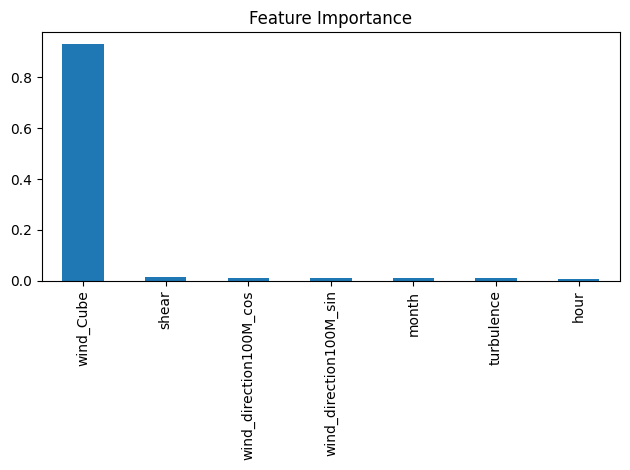

In [133]:
importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=False)

print(importance)

importance.plot(kind='bar')
plt.title('Feature Importance')
plt.tight_layout()
plt.show()

In [124]:
print(df['available_capacity'].value_counts())
print(df['available_capacity'].describe())

available_capacity
122400    30760
119000     9432
115600     7200
112200     2432
121550      936
118150      648
114750      612
108800      316
111350      108
0            40
98600        16
100000        4
105400        4
Name: count, dtype: int64
count     52508.000000
mean     120019.562733
std        4636.559770
min           0.000000
25%      119000.000000
50%      122400.000000
75%      122400.000000
max      122400.000000
Name: available_capacity, dtype: float64


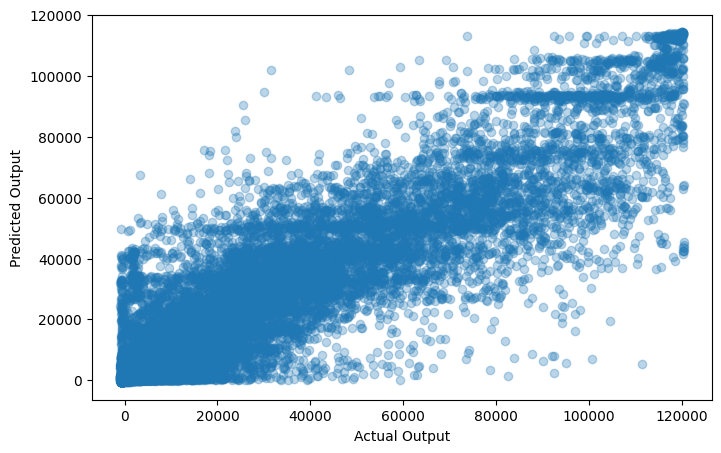

In [134]:
plt.figure(figsize=(8, 5))
plt.scatter(y_val_real, y_pred_real, alpha = 0.3)
plt.xlabel("Actual Output")
plt.ylabel("Predicted Output")
plt.show()

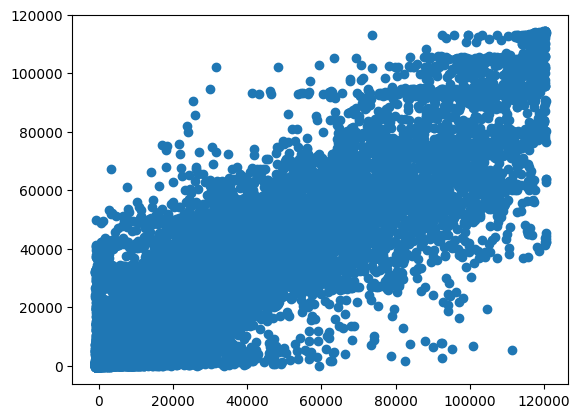

In [136]:
plt.scatter(y_val_real, y_pred_real)

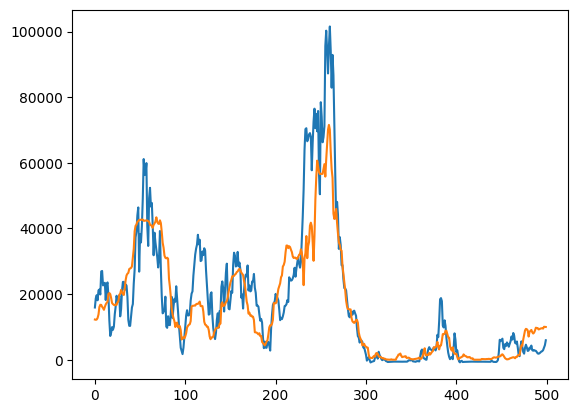

In [137]:
plt.plot(y_val_real.values[:500])
plt.plot(y_pred_real[:500])